<a href="https://colab.research.google.com/github/SofiaP2002/SeminarioDeGradoII/blob/main/Copia_de_Iter_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import json

filepath_version = '/content/version_dos_component.json'
try:
    # Intentar cargar directamente con pandas
    df_version = pd.read_json(filepath_version)
    print("El dataset de componentes y versiones se ha cargado exitosamente.")
    display(df_version.head())
except Exception as e:
    print(f"Ocurrió un error al cargar el JSON: {e}")

El dataset de componentes y versiones se ha cargado exitosamente.


,change_id,issue_id,Change_Type,Field,From_String,To_String,Creation_Date,Author_ID
0,111316,7759,OTHER,Component,None,Documentation,2015-04-03 23:45:09,1586
1,111329,7760,OTHER,Component,None,Documentation,2015-04-03 22:31:37,1586
2,111371,7763,OTHER,Component,None,Documentation,2015-04-03 22:11:44,1586
3,111392,7764,OTHER,Component,Chapter: Introduction,None,2009-09-10 23:10:18,2096
4,111417,7764,OTHER,Component,Front Matter,None,2014-12-16 21:41:50,1586


In [ ]:
pip install sentence-transformers

In [ ]:
import pandas as pd

# Filtrar df_version para asegurar que el componente (To_String) no sea nulo ni vacío
df_valid_components = df_version[df_version['To_String'].notna() & (df_version['To_String'] != 'None') & (df_version['To_String'].astype(str).str.strip() != '')]

# Obtener el primer componente cronológicamente para cada issue_id
df_first_component = df_valid_components.sort_values(by='Creation_Date').groupby('issue_id').first().reset_index()

# Mantener únicamente las columnas de identificación e interés
df_first_component = df_first_component[['issue_id', 'To_String']].rename(columns={'To_String': 'First_Component'})

print("Primeros componentes válidos por cada issue_id filtrados exitosamente.")
display(df_first_component.head())

Primeros componentes válidos por cada issue_id filtrados exitosamente.


,issue_id,First_Component
0,999,Documentation
1,1148,Packaging
2,3474,CLI
3,3765,Runtime
4,3768,Analytics


In [ ]:
import pandas as pd
import json

filepath_comments = '/content/version_dos_comentarios.json'
try:
    # Cargar el dataset de comentarios
    df_comments_version = pd.read_json(filepath_comments)
    print("El dataset de comentarios se ha cargado exitosamente. Columnas detectadas:", list(df_comments_version.columns))

    # Identificar la columna de fecha disponible
    date_col = 'Creation_Date' if 'Creation_Date' in df_comments_version.columns else ('comment_date' if 'comment_date' in df_comments_version.columns else None)

    # Filtrar para asegurar que el comentario no sea nulo ni vacío
    df_valid_comments = df_comments_version[
        df_comments_version['Comment'].notna() &
        (df_comments_version['Comment'].astype(str).str.strip() != '')
    ]

    # Obtener el primer comentario para cada issue_id ordenando por fecha si existe
    if date_col:
        df_first_comment = df_valid_comments.sort_values(by=date_col).groupby('issue_id').first().reset_index()
    else:
        df_first_comment = df_valid_comments.groupby('issue_id').first().reset_index()

    # Mantener únicamente las columnas de identificación e interés
    df_first_comment = df_first_comment[['issue_id', 'Comment']].rename(columns={'Comment': 'First_Comment'})

    print("Primeros comentarios válidos por cada issue_id filtrados exitosamente.")
    display(df_first_comment.head())
except Exception as e:
    print(f"Ocurrió un error al procesar el JSON de comentarios: {e}")

El dataset de comentarios se ha cargado exitosamente. Columnas detectadas: ['comment_id', 'issue_id', 'Comment', 'Comment_Text', 'Comment_Code', 'Creation_Date', 'Author_ID']
Primeros comentarios válidos por cada issue_id filtrados exitosamente.


,issue_id,First_Comment
0,999,If you use a dependency management tool such a...
1,3752,Based on the current performance test setup fo...
2,3758,main requirement here is a websocket sink (but...
3,6489,{quote}If the current responses of endpoints a...
4,6563,[~<EMAIL>] See http://books.sonatype.com/nexus...


## 1. Carga del Dataset


In [ ]:
import pandas as pd

filepath = '/content/version_dos_consolidado.json'
try:
    df = pd.read_json(filepath)
    print(f"El dataset consolidado '{filepath}' se ha cargado exitosamente.")
    display(df.head())
except FileNotFoundError:
    print(f"Error: El archivo '{filepath}' no se encontró. Asegúrate de que está en el directorio correcto.")
except Exception as e:
    print(f"Ocurrió un error al cargar o procesar el dataset: {e}")

El dataset consolidado '/content/version_dos_consolidado.json' se ha cargado exitosamente.


,ID,Jira_ID,Issue_Key,URL,Project_ID,Project_Key,project_name,Creator_ID,Creation_Date,fecha_estimacion_efectiva,...,description,priority,assignee_id,reporter_id,sprint_nombre,sprint_id,sprint_start_date,sprint_end_date,story_point_final,target
0,3760,48134,XD-15,https://jira.spring.io/rest/api/2/issue/48134,1,XD,Spring XD,72,2013-04-12 06:49:47,2013-04-12 06:49:47,...,,Minor,72.0,72.0,None,NaN,None,None,NaN,0
1,4626,758169,NEXUS-25307,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,472,2020-09-16 22:10:36,2020-09-16 22:10:36,...,"""A NXRM PM likes to ensure customers cannot de...",Major,NaN,472.0,None,NaN,None,None,NaN,0
2,4638,757438,NEXUS-25239,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:37:34,2020-09-10 11:37:34,...,p2 artifact repositories contain blocks which ...,Major,NaN,492.0,None,NaN,None,None,NaN,0
3,4639,757437,NEXUS-25238,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:36:04,2020-09-10 11:36:04,...,Github issue: [https://github.com/sonatype-nex...,Major,NaN,492.0,None,NaN,None,None,NaN,0
4,4640,757436,NEXUS-25237,https://issues.sonatype.org/rest/api/2/issue/7...,3,NEXUS,Sonatype Nexus,492,2020-09-10 11:32:32,2020-09-10 11:32:32,...,"""Github issue: [https://github.com/sonatype-ne...",Major,NaN,492.0,None,NaN,None,None,NaN,0


In [ ]:
# Unir el primer componente filtrado al DataFrame consolidado ('df' usa la columna 'ID' como identificador del issue)
df = df.merge(df_first_component, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id', 'Components_Lista'], errors='ignore')

# Unir el primer comentario filtrado al DataFrame consolidado
df = df.merge(df_first_comment, left_on='ID', right_on='issue_id', how='left').drop(columns=['issue_id'], errors='ignore')

print("Columnas del DataFrame consolidado tras integrar los datos:")
print(df.columns.tolist())

print("\nCantidad de valores no nulos en las nuevas columnas incorporadas:")
print(df[['First_Component', 'First_Comment']].notna().sum())

display(df[['ID', 'First_Component', 'First_Comment']].head(10))

Columnas del DataFrame consolidado tras integrar los datos:
['ID', 'Jira_ID', 'Issue_Key', 'URL', 'Project_ID', 'Project_Key', 'project_name', 'Creator_ID', 'Creation_Date', 'fecha_estimacion_efectiva', 'story_point_inicial', 'estado_al_corte', 'resolucion_al_corte', 'resolution_date_al_corte', 'title', 'description', 'priority', 'assignee_id', 'reporter_id', 'sprint_nombre', 'sprint_id', 'sprint_start_date', 'sprint_end_date', 'story_point_final', 'target', 'First_Component', 'First_Comment']

Cantidad de valores no nulos en las nuevas columnas incorporadas:
First_Component     707
First_Comment      2922
dtype: int64


,ID,First_Component,First_Comment
0,3760,NaN,NaN
1,4626,NaN,NaN
2,4638,NaN,NaN
3,4639,NaN,NaN
4,4640,NaN,NaN
5,4644,NaN,NaN
6,4663,NaN,NaN
7,4699,NaN,NaN
8,4700,NaN,NaN
9,4738,NaN,NaN


In [ ]:
import pandas as pd

# Asegurar que la fecha de estimación efectiva sea de tipo datetime para ordenar cronológicamente
df['fecha_estimacion_efectiva'] = pd.to_datetime(df['fecha_estimacion_efectiva'])

# Ordenar el DataFrame cronológicamente
df = df.sort_values(by='fecha_estimacion_efectiva').reset_index(drop=True)

# Crear la variable 'experiencia_en_proyecto': conteo acumulativo de tareas previas por asignado en cada proyecto
# Usamos cumcount() que inicia en 0 (la primera tarea del desarrollador tendrá experiencia 0, la segunda 1, etc.)
df['experiencia_en_proyecto'] = df.groupby(['Project_ID', 'assignee_id']).cumcount()

# Si no hay un asignado (assignee_id es NaN), rellenamos la experiencia con NaN o 0.
# En este caso, si no está asignado, tiene sentido dejarlo como 0 o mantenerlo como NaN si se prefiere imputar luego.
df.loc[df['assignee_id'].isna(), 'experiencia_en_proyecto'] = 0

print("Característica 'experiencia_en_proyecto' creada exitosamente de forma cronológica.")
display(df[['ID', 'fecha_estimacion_efectiva', 'Project_ID', 'assignee_id', 'experiencia_en_proyecto']].head(15))

Característica 'experiencia_en_proyecto' creada exitosamente de forma cronológica.


,ID,fecha_estimacion_efectiva,Project_ID,assignee_id,experiencia_en_proyecto
0,248745,2009-11-11 16:05:21,29,NaN,0.0
1,248744,2009-11-24 14:51:42,29,NaN,0.0
2,248743,2009-11-24 14:55:56,29,NaN,0.0
3,248740,2009-12-18 02:57:38,29,NaN,0.0
4,248739,2009-12-23 17:32:24,29,NaN,0.0
5,248725,2010-01-04 17:50:45,29,NaN,0.0
6,248723,2010-01-04 17:52:01,29,NaN,0.0
7,248721,2010-01-04 17:55:34,29,NaN,0.0
8,248716,2010-01-04 18:02:59,29,NaN,0.0
9,248715,2010-01-04 18:04:36,29,NaN,0.0


In [ ]:
columns_to_keep = [
        'title',
        'description',
        'priority',
        'story_point_inicial',
        'target',
        'First_Component',
        'First_Comment',
        'assignee_id',
        'reporter_id',
        'Project_ID',
        'experiencia_en_proyecto']
# Filter the DataFrame to keep only the specified columns
df = df[columns_to_keep]
print(f"El DataFrame ahora contiene solo las siguientes columnas: {columns_to_keep}")
print("Primeras 5 filas del DataFrame con las columnas seleccionadas:")
display(df.head())
print("Información del DataFrame actualizado:")
df.info()


El DataFrame ahora contiene solo las siguientes columnas: ['title', 'description', 'priority', 'story_point_inicial', 'target', 'First_Component', 'First_Comment', 'assignee_id', 'reporter_id', 'Project_ID', 'experiencia_en_proyecto']
Primeras 5 filas del DataFrame con las columnas seleccionadas:


,title,description,priority,story_point_inicial,target,First_Component,First_Comment,assignee_id,reporter_id,Project_ID,experiencia_en_proyecto
0,"""Memory-bound Space/Content iteration""","""The StorageProvider interface includes iterat...",Critical,NaN,0,NaN,NaN,NaN,146008.0,29,0.0
1,"""Meaningful response error codes needed""","""DuraStore service returns 500 error code for ...",Blocker,NaN,0,NaN,NaN,NaN,146008.0,29,0.0
2,"""ContentId / SpaceId validation library""","""May I suggest having a having a couple conven...",Minor,NaN,0,NaN,NaN,NaN,146007.0,29,0.0
3,"""Runtime configuration of duraservice & durast...","""duraservice.properties and durastore.properti...",Major,NaN,0,NaN,NaN,NaN,146007.0,29,0.0
4,"""Update Rackspace Java library""","""The Rackspace Java libraries have progressed ...",Minor,NaN,0,NaN,NaN,NaN,145992.0,29,0.0


Información del DataFrame actualizado:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31394 entries, 0 to 31393
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   title                    31394 non-null  object 
 1   description              30490 non-null  object 
 2   priority                 31361 non-null  object 
 3   story_point_inicial      22000 non-null  float64
 4   target                   31394 non-null  int64  
 5   First_Component          707 non-null    object 
 6   First_Comment            2922 non-null   object 
 7   assignee_id              21748 non-null  float64
 8   reporter_id              30524 non-null  float64
 9   Project_ID               31394 non-null  int64  
 10  experiencia_en_proyecto  31394 non-null  float64
dtypes: float64(4), int64(2), object(5)
memory usage: 2.6+ MB


In [ ]:
print("Consolidando 'Major - P3' en 'Major' y 'Minor - P4' en 'Minor' en la columna 'Priority'...")
# Replace 'Major - P3' with 'Major' and 'Minor - P4' with 'Minor'
df['priority'] = df['priority'].replace({
            'Major - P3': 'Major',
            'Minor - P4': 'Minor'
})
print("Consolidación completada. Mostrando el conteo de valores actualizados de 'Priority':")
display(df['priority'].value_counts(dropna=False))

Consolidando 'Major - P3' en 'Major' y 'Minor - P4' en 'Minor' en la columna 'Priority'...
Consolidación completada. Mostrando el conteo de valores actualizados de 'Priority':


,count
priority,
,19341
Medium,3443
Minor,2868
Major,1786
None,1357
High,1301
Low,492
Critical,297
Undefined,138


In [ ]:
print("Completando los valores nulos en la columna 'First_Component' con 'No Component'...")
df['First_Component'] = df['First_Component'].fillna('No Component')
print("Valores nulos en 'First_Component' completados. Mostrando el conteo de valores actualizado:")
display(df['First_Component'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'First_Component' con 'No Component'...
Valores nulos en 'First_Component' completados. Mostrando el conteo de valores actualizado:


,count
First_Component,
No Component,30687
Qserv,47
Documentation,22
Guides,20
Tooling,18
iOS,11
testing,11
Developer Infrastructure,11
Stack Documentation and UX,11


In [ ]:
print("Completando los valores nulos en la columna 'Priority' con 'No Priority'...")
df['priority'] = df['priority'].fillna('No Priority')
print("Valores nulos en 'Priority' completados. Mostrando el conteo de valores actualizado:")
display(df['priority'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'Priority' con 'No Priority'...
Valores nulos en 'Priority' completados. Mostrando el conteo de valores actualizado:


,count
priority,
,19341
Medium,3443
Minor,2868
Major,1786
None,1357
High,1301
Low,492
Critical,297
Undefined,138


In [ ]:
print("Completando los valores nulos en la columna 'First_Comment' con 'No Comment'...")
df['First_Comment'] = df['First_Comment'].fillna('No Comment')
print("Valores nulos en 'First_Comment' completados. Mostrando el conteo de los valores más comunes:")
display(df['First_Comment'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'First_Comment' con 'No Comment'...
Valores nulos en 'First_Comment' completados. Mostrando el conteo de los valores más comunes:


First_Comment
No Comment                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

In [ ]:
df['description'] = df['description'].fillna('No Description')
print("Valores nulos en 'Description_Estimacion_Inicial' completados. Mostrando el conteo de valores actualizado:")
display(df['description'].value_counts(dropna=False).head(10))

Valores nulos en 'Description_Estimacion_Inicial' completados. Mostrando el conteo de valores actualizado:


,count
description,
,4039
No Description,904
"""No description provided! This ticket had been created automatically Primavera ID: None""",102
"""Acceptance Criteria Needed""",26
"""Buckets for qe time tracking in JIRA""",23
No description provided!\n\nThis ticket had been created automatically\nPrimavera ID: None,16
"""h6.Reproduce Steps 1. Download any image of resolution(3264 X 2448) for testing purpose. (Attached test image) 2. Run the following example code in a default alloy app. 3. Drag the test image over to simulator. 4. Run the example app, click on the Hello World text of the application and select the testing image from the gallery. 5. Go to simulator folder, then check the saved image. For example in my test, the location is: (~/<USER>/⁨Library⁩/⁨Developer⁩/⁨CoreSimulator⁩/⁨Devices⁩/⁨9080930F-2320-4FF3-A042-D7955440EACE⁩/⁨data⁩/⁨Containers⁩/Data/⁨Application⁩/8D3292C5-4578-4B59-8956-29C36AB23BFF⁩/Documents⁩) h6.Problem Open the image, you will see the resolution is only 3073 X 2305 and it get cropped at right side and bottom side. h6.Expect The image should not get cropped.""",15
"""Collect, record, and verify financial data for the LSST Data Facility. Deliverable consists of a monthly financial report delivered to the Project Controls Specialist.""",14
"""See Summary""",13


### 7. Manejo de Outliers en 'Story_Point_Original' (elimina negativos y nulos)

In [ ]:
if 'df' in locals() and df is not None:
    # Registrar tamaño antes de filtrar
    initial_shape = df.shape[0]

    # Filtrar eliminando valores negativos de story_point_inicial
    df = df[df['story_point_inicial'] >= 0].copy()

    final_shape = df.shape[0]
    print(f"Filas iniciales: {initial_shape}")
    print(f"Filas tras eliminar Story Points negativos: {final_shape}")
    print(f"Valores eliminados: {initial_shape - final_shape}")
else:
    print("El DataFrame 'df' no está definido en el entorno.")

Filas iniciales: 31394
Filas tras eliminar Story Points negativos: 21999
Valores eliminados: 9395


### 7. Manejo de Outliers en 'Story_Point_Original' completando nulos


In [ ]:
print("Imputando los valores nulos de 'story_point_inicial' con la mediana de su respectivo 'Project_ID'...")
df['story_point_inicial'] = df.groupby('Project_ID')['story_point_inicial'].transform(lambda x: x.fillna(x.median()))

# Si aún quedan nulos debido a proyectos sin ningún valor de SP registrado, completamos con la mediana global
global_median = df['story_point_inicial'].median()
df['story_point_inicial'] = df['story_point_inicial'].fillna(global_median)

print("Valores nulos en 'story_point_inicial' completados exitosamente.")
print(f"Nulos restantes en la columna: {df['story_point_inicial'].isnull().sum()}")
display(df['story_point_inicial'].describe())

Imputando los valores nulos de 'story_point_inicial' con la mediana de su respectivo 'Project_ID'...
Valores nulos en 'story_point_inicial' completados exitosamente.
Nulos restantes en la columna: 0


,story_point_inicial
count,21999.000000
mean,4.447137
std,12.700067
min,0.000000
25%,1.000000
50%,3.000000
75%,5.000000
max,1010.000000


In [ ]:
print("Completando los valores nulos en la columna 'reporter_id' con -1.0...")
df['reporter_id'] = df['reporter_id'].fillna(-1.0)
print("Valores nulos en 'reporter_id' completados exitosamente.")
print(f"Nulos restantes en 'reporter_id': {df['reporter_id'].isnull().sum()}")
display(df['reporter_id'].value_counts(dropna=False).head(10))

Completando los valores nulos en la columna 'reporter_id' con -1.0...
Valores nulos en 'reporter_id' completados exitosamente.
Nulos restantes en 'reporter_id': 0


,count
reporter_id,
145778.0,854
145726.0,766
145807.0,741
78.0,595
145874.0,566
72.0,553
-1.0,507
145769.0,490
145720.0,475


#PRUEBA

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, average_precision_score, roc_auc_score, balanced_accuracy_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
warnings.filterwarnings('ignore')

if 'df' in locals() and df is not None:
    # 1. Definir la variable objetivo
    y = df['target'].astype(int)

    # 2. Crear la característica de texto combinado en una copia del DataFrame para X
    df_model = df.copy()
    df_model['Texto_Combinado'] = (
        df_model['title'].fillna('') + ' ' +
        df_model['description'].fillna('')
    )
    df_model['First_Component'] = df_model['First_Component'].fillna('').astype(str)
    df_model['priority'] = df_model['priority'].fillna('No Priority')
    df_model['reporter_id'] = df_model['reporter_id'].fillna('No Reporter').astype(str)
    df_model['experiencia_en_proyecto'] = df_model['experiencia_en_proyecto'].fillna(0)

    # 3. Definir características
    numerical_features = [
        'story_point_inicial',
        'experiencia_en_proyecto'
    ]
    categorical_features = [
        'priority',
        'reporter_id'
    ]

    text_feature_col = 'Texto_Combinado'
    components_text_col = 'First_Component'

    features_to_use = numerical_features + categorical_features + [text_feature_col] + [components_text_col]
    X = df_model[features_to_use]

    # 4. Dividir los datos aplicando el test_size del 20%
    train_val_pct = 0.20
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X, y, test_size=train_val_pct, random_state=42
    )

    print("Forma de los datos después de la división:")
    print(f"X_train_raw: {X_train_raw.shape}, X_test_raw: {X_test_raw.shape}")
    print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

    # 5. Preprocesamiento usando ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_features),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=True), categorical_features),
            ('text_tfidf_desc_title', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=3, max_df=0.95, ngram_range=(1, 2), max_features=10000), text_feature_col),
            ('text_tfidf_components', TfidfVectorizer(lowercase=True, strip_accents='unicode', sublinear_tf=True,
                                          min_df=1, max_df=0.95, ngram_range=(1, 1), max_features=100), components_text_col)
        ],
        remainder='passthrough',
        verbose_feature_names_out=False
    )

    # Ajustar preprocesamiento con train y transformar ambos
    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    print("\nDimensiones de las características transformadas:")
    print(f"X_train: {X_train.shape}")
    print(f"X_test: {X_test.shape}")

    # Función para mostrar los resultados
    def mostrar_resultados(y_true, y_pred_values, y_pred_proba=None):
        LABELS = sorted(y_true.unique().astype(str))
        conf_matrix = confusion_matrix(y_true, y_pred_values)
        plt.figure(figsize=(12, 12))
        ax = sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d",
                    annot_kws={"size": 20})
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        plt.title("Confusion matrix")
        plt.ylabel("True class", fontsize=22)
        plt.xlabel("Predicted class", fontsize=22)
        plt.show()
        print(classification_report(y_true, y_pred_values))

        balanced_acc = balanced_accuracy_score(y_true, y_pred_values)
        print(f"Balanced Accuracy: {balanced_acc:.4f}")

        if y_pred_proba is not None:
            avg_precision = average_precision_score(y_true, y_pred_proba)
            roc_auc = roc_auc_score(y_true, y_pred_proba)
            print(f"Average Precision (PR-AUC): {avg_precision:.4f}")
            print(f"ROC AUC: {roc_auc:.4f}")
            print("\nPrimeras 10 predicciones - Real vs Predicha vs Probabilidad:")
            sample_df = pd.DataFrame({
                'Real': y_true.reset_index(drop=True).head(10),
                'Predicha': pd.Series(y_pred_values).head(10),
                'Probabilidad': pd.Series(y_pred_proba).head(10)
            })
            display(sample_df)

else:
    print("El DataFrame 'df' no está disponible o no se cargó correctamente.")


Forma de los datos después de la división:
X_train_raw: (17599, 6), X_test_raw: (4400, 6)
y_train: (17599,), y_test: (4400,)

Dimensiones de las características transformadas:
X_train: (17599, 10692)
X_test: (4400, 10692)


#Modelos

Random forest

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, precision_score, recall_score, classification_report, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

# Crear y entrenar el RandomForestClassifier con los hiperparámetros solicitados
clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    class_weight="balanced",
    n_jobs=-1,
    random_state=1
).fit(X_train, y_train)


In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, precision_score, recall_score, classification_report, f1_score
from sklearn.linear_model import LogisticRegression

# Crear y entrenar el clasificador de Regresión Logística en el formato original solicitado
clf = LogisticRegression(
    C=1.0,
    penalty='l2',
    random_state=1,
    solver="saga", # Usar 'saga' para consistencia y soporte de 'balanced' class_weight
    max_iter=2000, # Aumentar max_iter para asegurar convergencia
    class_weight="balanced"
).fit(X_train, y_train)

--- MÉTRICAS EN EL CONJUNTO DE TEST (UMBRAL MANUAL: 0.14) ---
Model accuracy          : 0.2545
Precision (Clase 1)     : 0.2063
Recall/Exhaustividad (1): 0.9803
F1-Score (Clase 1)      : 0.3408
PR-AUC (Average Prec.)  : 0.3816
ROC-AUC                 : 0.6974

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.08      0.14      3535
           1       0.21      0.98      0.34       865

    accuracy                           0.25      4400
   macro avg       0.57      0.53      0.24      4400
weighted avg       0.80      0.25      0.18      4400



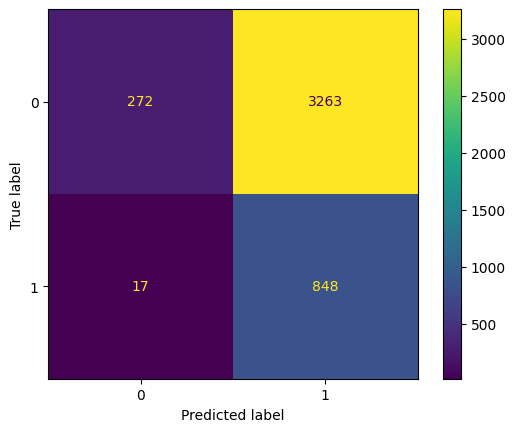

In [ ]:
# Performance on the test-data
test_pred_prob = clf.predict_proba(X_test)[:, 1]

# Definir el umbral de decisión manual
umbral_manual = 0.14

# Obtener las predicciones utilizando el umbral configurado
test_preds = (test_pred_prob >= umbral_manual).astype(int)

# Calcular métricas individuales para la clase positiva (1)
prec = precision_score(y_test, test_preds, pos_label=1, zero_division=0)
rec = recall_score(y_test, test_preds, pos_label=1, zero_division=0)
f1 = f1_score(y_test, test_preds, pos_label=1, zero_division=0)
pr_auc = average_precision_score(y_test, test_pred_prob)
roc_auc = roc_auc_score(y_test, test_pred_prob)

print(f"--- MÉTRICAS EN EL CONJUNTO DE TEST (UMBRAL MANUAL: {umbral_manual}) ---")
print(f"Model accuracy          : {accuracy_score(y_test, test_preds):.4f}")
print(f"Precision (Clase 1)     : {prec:.4f}")
print(f"Recall/Exhaustividad (1): {rec:.4f}")
print(f"F1-Score (Clase 1)      : {f1:.4f}")
print(f"PR-AUC (Average Prec.)  : {pr_auc:.4f}")
print(f"ROC-AUC                 : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, test_preds))

# Matriz de confusión
cm = confusion_matrix(y_test, test_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
disp.plot()


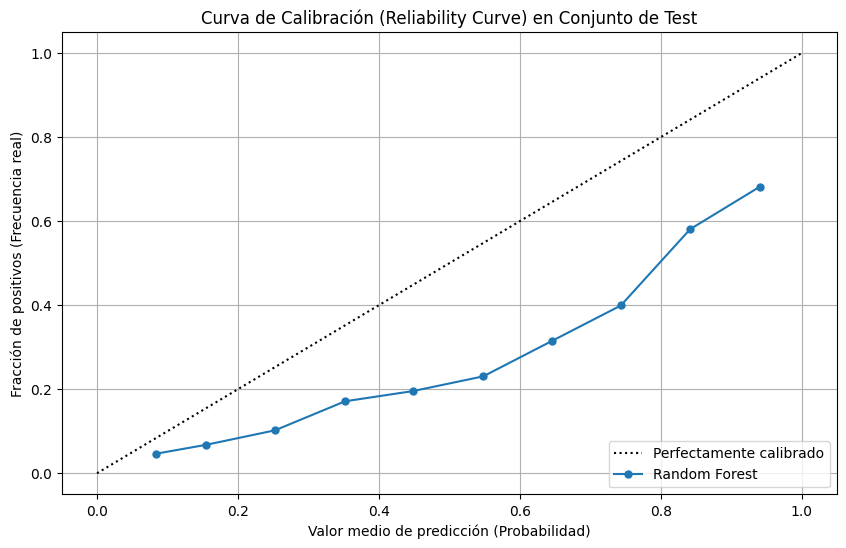

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Obtener las probabilidades de predicción para el conjunto de test
test_preds_proba = clf.predict_proba(X_test)[:, 1]

# Calcular la curva de calibración sobre el conjunto de test
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test, test_preds_proba, n_bins=10, strategy='uniform'
)

plt.figure(figsize=(10, 6))
plt.plot([0, 1], [0, 1], 'k:', label="Perfectamente calibrado")
plt.plot(mean_predicted_value, fraction_of_positives, marker='.', markersize=10, label="Random Forest")

plt.xlabel("Valor medio de predicción (Probabilidad)")
plt.ylabel("Fracción de positivos (Frecuencia real)")
plt.title("Curva de Calibración (Reliability Curve) en Conjunto de Test")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


In [ ]:
from sklearn.calibration import CalibratedClassifierCV

# Calibración usando el método de Platt (Sigmoide) con validación cruzada interna para evitar sobreajuste
cal_clf_plat = CalibratedClassifierCV(clf, method="sigmoid", cv=5)
cal_clf_plat.fit(X_train, y_train)

# Obtener las probabilidades calibradas en el conjunto de test
test_preds_cal_plat = cal_clf_plat.predict_proba(X_test)[:, 1]

# Calibración usando Regresión Isotónica con validación cruzada interna
cal_clf_iso = CalibratedClassifierCV(clf, method="isotonic", cv=5)
cal_clf_iso.fit(X_train, y_train)

# Obtener las probabilidades calibradas en el conjunto de test
test_preds_cal_iso = cal_clf_iso.predict_proba(X_test)[:, 1]

print("Modelos de calibración ajustados exitosamente con validación cruzada.")

Modelos de calibración ajustados exitosamente con validación cruzada.


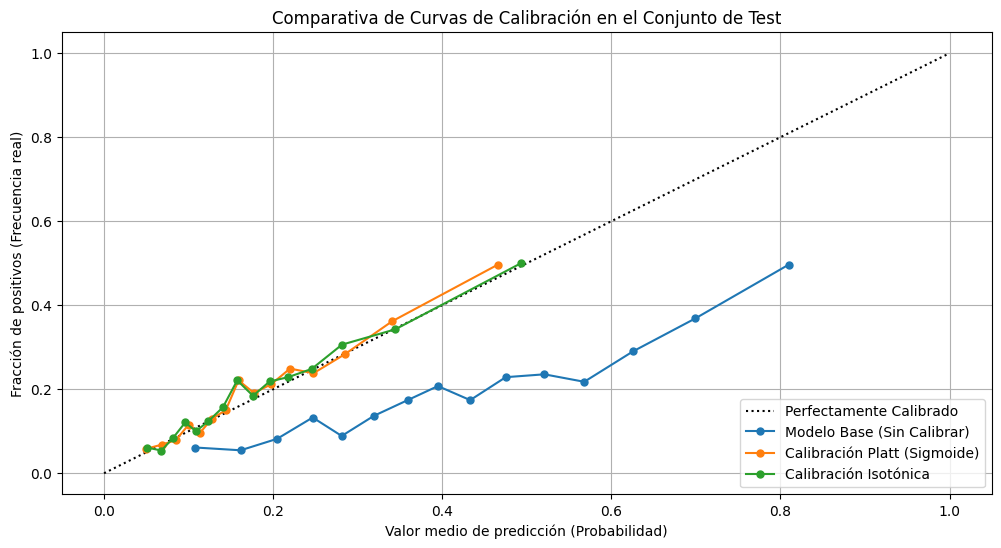

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Calcular curvas de calibración usando el conjunto de prueba para una evaluación justa
fraction_of_positives_plain, mean_predicted_value_plain = calibration_curve(y_test, test_preds_proba, n_bins=15, strategy='quantile')
fraction_of_positives_plat, mean_predicted_value_plat = calibration_curve(y_test, test_preds_cal_plat, n_bins=15, strategy='quantile')
fraction_of_positives_iso, mean_predicted_value_iso = calibration_curve(y_test, test_preds_cal_iso, n_bins=15, strategy='quantile')

plt.figure(figsize=(12, 6))
plt.plot([0, 1], [0, 1], 'k:', label="Perfectamente Calibrado")
plt.plot(mean_predicted_value_plain, fraction_of_positives_plain, marker='.', markersize=10, label='Modelo Base (Sin Calibrar)')
plt.plot(mean_predicted_value_plat, fraction_of_positives_plat, marker='.', markersize=10, label='Calibración Platt (Sigmoide)')
plt.plot(mean_predicted_value_iso, fraction_of_positives_iso, marker='.', markersize=10, label='Calibración Isotónica')

plt.legend(loc="lower right")
plt.xlabel("Valor medio de predicción (Probabilidad)")
plt.ylabel("Fracción de positivos (Frecuencia real)")
plt.title("Comparativa de Curvas de Calibración en el Conjunto de Test")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import brier_score_loss

# Calcular Brier score sobre el conjunto de test (usando pos_label=1 para clases binarias 0/1)
model_bs = brier_score_loss(y_test, test_preds_proba, pos_label=1)
plat_bs = brier_score_loss(y_test, test_preds_cal_plat, pos_label=1)
iso_bs = brier_score_loss(y_test, test_preds_cal_iso, pos_label=1)

print("Rendimiento en el Conjunto de Test (Brier Score - Menor es mejor):\n")
print("Plain Model Brier score        : {0:.4f}".format(model_bs))
print("Platt-Scaling Brier score      : {0:.4f}".format(plat_bs))
print("Isotonic Regression Brier score: {0:.4f}".format(iso_bs))

Rendimiento en el Conjunto de Test (Brier Score - Menor es mejor):

Plain Model Brier score        : 0.1992
Platt-Scaling Brier score      : 0.1438
Isotonic Regression Brier score: 0.1437


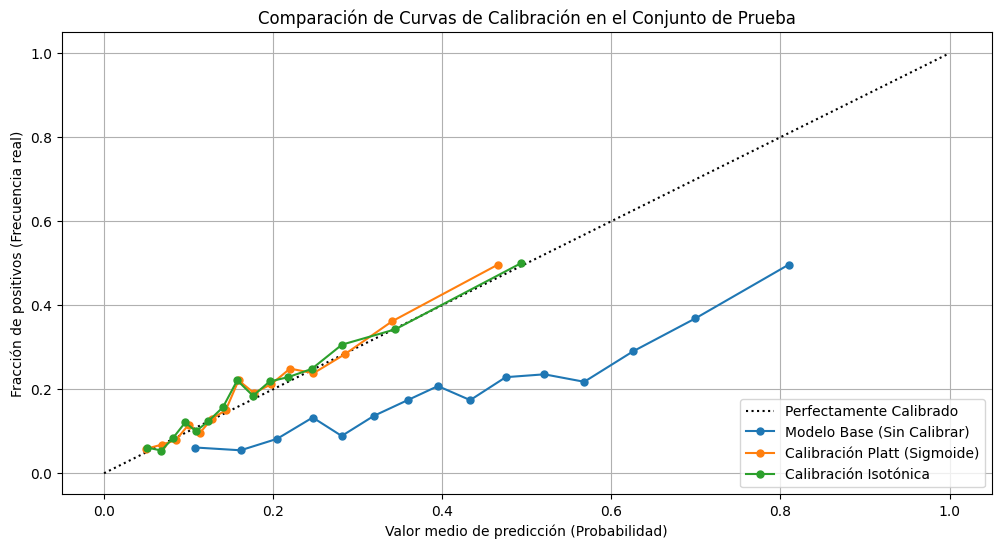

In [ ]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

# Obtener las probabilidades (valores continuos entre 0 y 1) para el conjunto de prueba
proba_original = clf.predict_proba(X_test)[:, 1]
proba_plat = cal_clf_plat.predict_proba(X_test)[:, 1]
proba_iso = cal_clf_iso.predict_proba(X_test)[:, 1]

# Calcular curvas de calibración utilizando la estrategia 'quantile' y 15 bins
df_tmp = calibration_curve(y_test, proba_original, n_bins=15, strategy='quantile')
df_tmp2 = calibration_curve(y_test, proba_plat, n_bins=15, strategy='quantile')
df_tmp3 = calibration_curve(y_test, proba_iso, n_bins=15, strategy='quantile')

plt.figure(figsize=(12, 6))
plt.plot([0, 1], [0, 1], 'k:', label="Perfectamente Calibrado")
plt.plot(df_tmp[1], df_tmp[0], marker='.', markersize=10, label='Modelo Base (Sin Calibrar)')
plt.plot(df_tmp2[1], df_tmp2[0], marker='.', markersize=10, label='Calibración Platt (Sigmoide)')
plt.plot(df_tmp3[1], df_tmp3[0], marker='.', markersize=10, label='Calibración Isotónica')

plt.legend(loc="lower right")
plt.xlabel("Valor medio de predicción (Probabilidad)")
plt.ylabel("Fracción de positivos (Frecuencia real)")
plt.title("Comparación de Curvas de Calibración en el Conjunto de Prueba")
plt.grid(True)
plt.show()

In [ ]:
model_bs, plat_bs, iso_bs = brier_score_loss(y_test, test_preds, pos_label=1), brier_score_loss(y_test, test_preds_cal_plat, pos_label=1), brier_score_loss(y_test, test_preds_cal_iso, pos_label=1)

print("Performance Test-set\n")
print("Plain Model Brier score : {0}\nPlatt-Scaling Brier score: {1}\nIsotonic Regression Brier score: {2}".format(model_bs, plat_bs, iso_bs))

Performance Test-set

Plain Model Brier score : 0.7454545454545455
Platt-Scaling Brier score: 0.1438129821767273
Isotonic Regression Brier score: 0.14367729258317144


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc, average_precision_score

# Performance on the test-data aplicando el umbral manual y obteniendo métricas detalladas para ambas clases
umbral_manual = 0.16
models = {clf: 'Plain Model', cal_clf_plat: 'Platt Scaling', cal_clf_iso: 'Isotonic Regression'}

for clf_tmp, name in models.items():
    print(f"=== {name} (Umbral: {umbral_manual}) ===")
    # Obtener probabilidades estimadas para la clase 1
    test_pred_prob = clf_tmp.predict_proba(X_test)[:, 1]
    # Aplicar el umbral configurado
    test_preds = (test_pred_prob >= umbral_manual).astype(int)

    print(f'Model accuracy          : {accuracy_score(y_test, test_preds):.4f}')
    cm = confusion_matrix(y_test, test_preds)
    print('Confusion matrix :\n', cm)

    # Mostrar el reporte detallado de clasificación para ambas clases (0 y 1)
    print('\nClassification Report (Ambas Clases):')
    print(classification_report(y_test, test_preds, labels=[0, 1], digits=4))

    print(f"PR-AUC (Average Prec.)  : {average_precision_score(y_test, test_pred_prob):.4f}")
    fpr, tpr, thresholds = roc_curve(y_test, test_pred_prob, pos_label=1)
    print(f'ROC-AUC                 : {auc(fpr, tpr):.4f}\n')
    print("=" * 40 + "\n")

=== Plain Model (Umbral: 0.16) ===
Model accuracy          : 0.2832
Confusion matrix :
 [[ 409 3126]
 [  28  837]]

Classification Report (Ambas Clases):
              precision    recall  f1-score   support

           0     0.9359    0.1157    0.2059      3535
           1     0.2112    0.9676    0.3467       865

    accuracy                         0.2832      4400
   macro avg     0.5736    0.5417    0.2763      4400
weighted avg     0.7935    0.2832    0.2336      4400

PR-AUC (Average Prec.)  : 0.3816
ROC-AUC                 : 0.6974


=== Platt Scaling (Umbral: 0.16) ===
Model accuracy          : 0.5905
Confusion matrix :
 [[1981 1554]
 [ 248  617]]

Classification Report (Ambas Clases):
              precision    recall  f1-score   support

           0     0.8887    0.5604    0.6874      3535
           1     0.2842    0.7133    0.4065       865

    accuracy                         0.5905      4400
   macro avg     0.5865    0.6368    0.5469      4400
weighted avg     0.7699